# APPL y Coca Cola

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import math
import matplotlib.pyplot as plt

## 2 Carteras de activos financieros


In [2]:
# Tickers and time
stocks_list = 'AAPL KO'
start_date = '2020-01-01'
end_date = '2025-01-01'

In [3]:
data = yf.download(
    tickers=stocks_list,
    start=start_date,
    end=end_date,
    interval="1mo",
    auto_adjust=True
)['Close'].dropna()
data.head()

[*********************100%***********************]  2 of 2 completed


Ticker,AAPL,KO
Date,,
2020-01-01,74.475677,47.656162
2020-02-01,65.933189,43.649460
2020-03-01,61.333603,36.426006
2020-04-01,70.863235,37.776051
2020-05-01,76.893280,38.426350


# Análisis estadístico

In [4]:
monthly_ret = np.log(data).diff().dropna() # Montly return
ret=np.array(monthly_ret*12) # Annual return
print("Stocks Monthly Returns:")
print(monthly_ret.head())
print(type(monthly_ret))

Stocks Monthly Returns:
Ticker          AAPL        KO
Date                          
2020-02-01 -0.121831 -0.087821
2020-03-01 -0.072314 -0.180908
2020-04-01  0.144424  0.036392
2020-05-01  0.081667  0.017068
2020-06-01  0.137487 -0.034745
<class 'pandas.core.frame.DataFrame'>


In [5]:
# Mean Returns
mean_ret = monthly_ret.mean()
print("Stocks Mean Returns:")
print(mean_ret*12)

Stocks Mean Returns:
Ticker
AAPL    0.245173
KO      0.044541
dtype: float64


In [6]:
# Sigma
sigma = monthly_ret.std()
print("Stocks Sigma:")
print(sigma*np.sqrt(12))


Stocks Sigma:
Ticker
AAPL    0.284912
KO      0.191014
dtype: float64


### Teoría de Carteras

Una **cartera** de activos define una colección de activos financieros, tales como acciones, bonos y otros instrumentos de inversión. La composición de la cartera se determina con el **objetivo** de alcanzar una meta financiera específica, como maximizar el rendimiento, minimizar el riesgo o encontrar un determinado equilibrio entre ambos. La **gestión** de carteras implica tomar decisiones estratégicas sobre la asignación de activos, la diversificación y el ajuste periódico para adaptarse a los posibles cambios en las condiciones del mercado.

Definir una cartera de activos implica especificar los diferentes instrumentos financieros o activos que la componen y la proporción en la que se invierte en cada uno. Si llamamos:

* $w_1$ a la proporción de la inversión en el activo $1$ $\Rightarrow w_2=1-w_1$. Debe cumplirse que $w_1 + w_2 = 1.0$, ya que esto representa el 100% de la inversión.

* $\bar R_p$ es el rendimiento medio o esperado de la cartera $\Rightarrow \bar R_p=w_1 \bar R_1 + w_2 \bar R_2$. Es una suma ponderada del rendimiento de cada activo por el porcentaje de inversión $w_i$ en cada uno de ellos.

* Varianza $\sigma_{P}^2 = w_1^2 \sigma_{1}^2 + w_2^2 \sigma_{2}^2 + 2 w_1 w_2 \sigma_{12}$ donde $\sigma_{12}$ es la covarianza entre los activos 1 y 2. En otras palabras, la varianza de la cartera se ve afectada por las covarianzas ($\sigma_{12}$) entre los activos.

* Volatilidad $\sigma_{P} = \sqrt{\sigma_{P}^2}$

Operando un poco y expresando la covarianza en función de la correlación:

$\sigma_{P}^2 = w_1^2 \sigma_{1}^2 + w_2^2 \sigma_{2}^2 + 2 w_1 w_2 \sigma_{12}$ donde $\sigma_{12} = Cov(r_1,r_2)$

Si:

$Corr(r_1,r_2) = \frac{Cov(r_1,r_2)} {\sigma_{r_1}\sigma_{r_2}} \implies Cov(r_1,r_2) = \sigma_{r_1}\sigma_{r_2} Corr(r_1,r_2) = \sigma_1\sigma_2 \rho_{12}$

Por lo tanto:

$\sigma_{P}^2 = w_1^2 \sigma_{1}^2 + w_2^2 \sigma_{2}^2 + 2 w_1 w_2 \sigma_1\sigma_2 \rho_{12} \implies \sigma_{P} = \sqrt{w_1^2 \sigma_{1}^2 + w_2^2 \sigma_{2}^2 + 2 w_1 w_2 \sigma_1\sigma_2 \rho_{12}}$

Crea una cartera equiponderada

In [7]:
Xa = 0.5
Xb = 1 - Xa
Portfolio_mean=Xa*mean_ret['AAPL']+Xb*mean_ret['KO']
print(Portfolio_mean)

0.012071435190404187


In [8]:
# Variance Covariance Matrix
df_cov_mat = monthly_ret.cov()
cov_mat=np.array(monthly_ret.cov()*12) # matriz de covarianzas anualizada en matriz
print("Variance-Covariance Matrix:")
print(df_cov_mat)

Variance-Covariance Matrix:
Ticker      AAPL        KO
Ticker                    
AAPL    0.006765  0.001773
KO      0.001773  0.003041


In [9]:
Porflio_sigma=(Xa**2*df_cov_mat.iloc[0,0]+Xb**2*df_cov_mat.iloc[1,1]+2*Xa*Xb*df_cov_mat.iloc[0,1])**0.5


# Generamos carteras con dos activos
Representar gráficamente las carteras que puedo construir asumiendo que tomamos una posición corta de -7.5 en Apple e incrementamos la inversión de a 0.5 hasta llegar a 4.5.

![Posiciones cortas 1](../imgs/posiciones_cortas_1.jpg)



![IPosiciones cortas 2](../imgs/posiciones_cortas_2.jpg)


![Posiciones cortas 3](../imgs/posiciones_cortas_3.jpg)


![Resultado](../imgs/posiciones_cortas_resultado.jpg)


* Fuente: Hull (2018)

In [10]:
# Weights
aapl_weight = np.arange(-7.5,4.5,0.5)
k_weight = 1-aapl_weight
aapl_weight

array([-7.5, -7. , -6.5, -6. , -5.5, -5. , -4.5, -4. , -3.5, -3. , -2.5,
       -2. , -1.5, -1. , -0.5,  0. ,  0.5,  1. ,  1.5,  2. ,  2.5,  3. ,
        3.5,  4. ])

In [11]:
# Portfolio returns
port_z_ret = aapl_weight * mean_ret[0] +k_weight* mean_ret[1]
port_z_ret

/tmp/ipykernel_1863/3410921883.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  port_z_ret = aapl_weight * mean_ret[0] +k_weight* mean_ret[1]


array([-0.1216835 , -0.11332382, -0.10496414, -0.09660445, -0.08824477,
       -0.07988508, -0.0715254 , -0.06316572, -0.05480603, -0.04644635,
       -0.03808667, -0.02972698, -0.0213673 , -0.01300762, -0.00464793,
        0.00371175,  0.01207144,  0.02043112,  0.0287908 ,  0.03715049,
        0.04551017,  0.05386985,  0.06222954,  0.07058922])

In [12]:
#  Portfolio returns
port_z_ret = aapl_weight * mean_ret['AAPL'] +k_weight* mean_ret['KO']
port_z_ret


array([-0.1216835 , -0.11332382, -0.10496414, -0.09660445, -0.08824477,
       -0.07988508, -0.0715254 , -0.06316572, -0.05480603, -0.04644635,
       -0.03808667, -0.02972698, -0.0213673 , -0.01300762, -0.00464793,
        0.00371175,  0.01207144,  0.02043112,  0.0287908 ,  0.03715049,
        0.04551017,  0.05386985,  0.06222954,  0.07058922])

In [13]:
# Portfolios Sigma
port_z_sigma = (aapl_weight ** 2 * df_cov_mat.iloc[0,0] + k_weight ** 2 * df_cov_mat.iloc[1,1] +
                2* (aapl_weight * k_weight) * df_cov_mat.iloc[0,1] ) ** 0.5
port_z_sigma

array([0.6116845 , 0.57228337, 0.53290559, 0.49355676, 0.45424439,
       0.41497885, 0.37577481, 0.33665377, 0.29764845, 0.25881118,
       0.22023088, 0.18207098, 0.14466455, 0.10879158, 0.07663661,
       0.05514092, 0.05777247, 0.08224708, 0.11541791, 0.1516832 ,
       0.1892725 , 0.22753055, 0.26616914, 0.3050437 ])

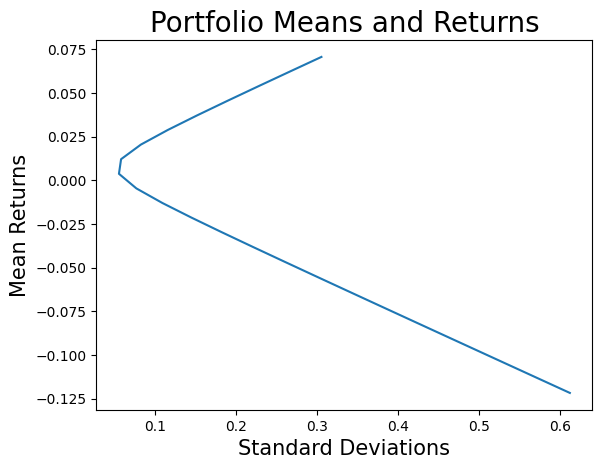

In [14]:
#Scatter Plot
plt.plot(port_z_sigma, port_z_ret) # envelope


# Titles and axes names
plt.title('Portfolio Means and Returns', fontsize = 20)
plt.xlabel('Standard Deviations', fontsize = 15)
plt.ylabel('Mean Returns', fontsize = 15)

# Show plot
plt.show()
